# 3.3.0-Clustering Level 2

**Inés Sentís**

Date of execution

In [1]:
Sys.Date()

[1] "2025-11-27"

## Libraries

In [2]:
options(warn = -1, verbose = FALSE)
suppressMessages(suppressWarnings({
library(Signac)
library(Seurat)
library(tidyverse)
library(ggplot2)
library(gridExtra)
library(scran)
library(scater)
}))

## Parameters

In [3]:
patient <- "p7"
subproj <- "AVGUSTINOVA_04_05"

assay_ch <- "RNA_decontx"

In [4]:
source(here::here(glue::glue("{subproj}/multiome_analysis/misc/paths.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/style.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/variables.R")))
source(here::here(glue::glue("utils/bin.R")))

"{clust}/{plt_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

"{clust}/{robj_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

set.seed(0)

In [5]:
var_name <- paste0("colors_", patient)
colors_list <- get(var_name)

In [6]:
var_name <- paste0("comp_", patient)
dcomp <- get(var_name)
dcomp

$rna
 [1]  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20

$atac
 [1]  2  3  4  5  6  7  8  9 10 11 12 13 14 15

In [7]:
var_name <- paste0("topc_", patient)
top_counts <- get(var_name)
top_counts

[1] "MALAT1"

In [8]:
var_name <- paste0("reso_l1_", patient)
reso <- get(var_name)
reso

[1] 0.15

## Load data

In [9]:
seurat_obj <- readRDS(here::here(glue::glue("{clust}/{robj_dir}/level_1/3.2.0-l1_anno_{patient}.rds")))
DefaultAssay(seurat_obj) <- assay_ch

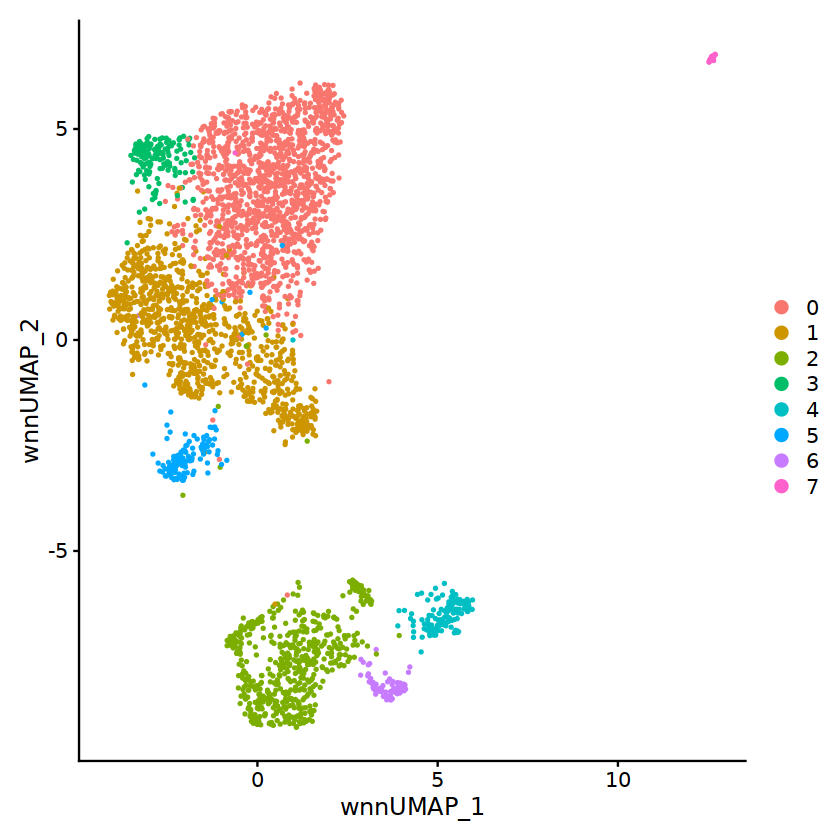

In [10]:
DimPlot(seurat_obj, reduction = "wnn.umap") 

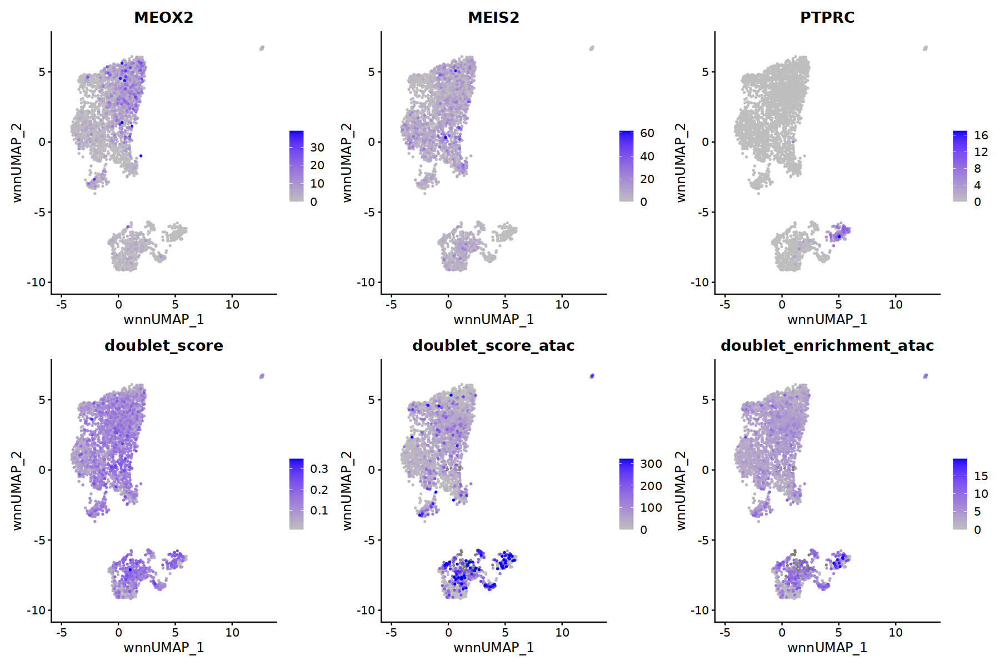

In [11]:
options(repr.plot.width = 15, repr.plot.height = 10)
FeaturePlot(seurat_obj, reduction = "wnn.umap", 
            feature=c("MEOX2","MEIS2","PTPRC",
                      "doublet_score","doublet_score_atac","doublet_enrichment_atac"), 
            ncol=3,cols = c("gray", "blue"),  order=T)

## Re-normalize

In [12]:
DefaultAssay(seurat_obj) <- assay_ch

In [13]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <- seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ]
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [14]:
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [15]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj, assay=assay_ch)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

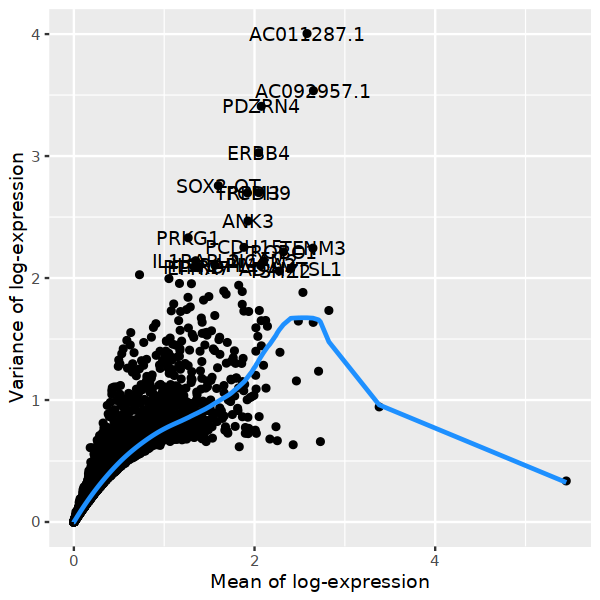

In [16]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [17]:
print(length(hvgs))
hvgs <- setdiff(hvgs, top_counts)
print(length(hvgs))

[1] 1056
[1] 1056


In [18]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  AC092957.1, AC011287.1, PCDH15, HMGA2, TRPM3, PDZRN4, ERBB4, ANK3, GAS2, PCDH9 
	   MAP2, GRIP1, CUX2, EPHA7, IL1RAPL2, TOX, RMST, SOX2-OT, FGFR2, BRINP3 
	   LINC02506, SOX6, SEMA3E, SHROOM3, ADGRV1, NXPH1, SEMA3D, VWDE, SCN3A, FIGN 
Negative:  UBE2E2, COL4A2, COL4A1, COL3A1, RUNX1, IGFBP7, COL6A3, EBF1, ZEB2, COL1A1 
	   STARD13, ITGA1, ATXN1, ADAMTS12, COL12A1, CCDC102B, FN1, DOCK10, PDZRN3, MIR4435-2HG 
	   CYTOR, MAN1A1, LAMB1, MYO1B, BICC1, OSMR, LDB2, DCN, GUCY1A2, PPP3CA 
PC_ 2 
Positive:  SLIT2, COL1A2, DLC1, PRKG1, COL5A2, CALD1, COL6A3, CCDC102B, PRRX1, PDZRN3 
	   LAMA4, COL1A1, ADAMTS12, TENM4, LHFPL6, COL12A1, BICC1, LAMA2, COL3A1, CDH11 
	   ITGA1, COL4A2, DCN, PRICKLE1, COL5A1, COL6A1, GUCY1A2, GUCY1A1, EDNRA, FN1 
Negative:  DOCK2, PTPRC, SYK, FMN1, ATP8B4, TBXAS1, NPL, DOCK8, MSR1, LYN 
	   IKZF1, HCK, ADAP2, LCP2, PIK3R5, PIK3AP1, STAB1, MRC1, CD163L1, SLCO2B1 
	   CYBB, SPP1, SRGN, TFEC, VAV3, CD163, ARHGAP15, ARH

In [19]:
markers = c("COL3A1","SEMA3E","ERBB4", "ANK3","MEOX2","PTPRC")

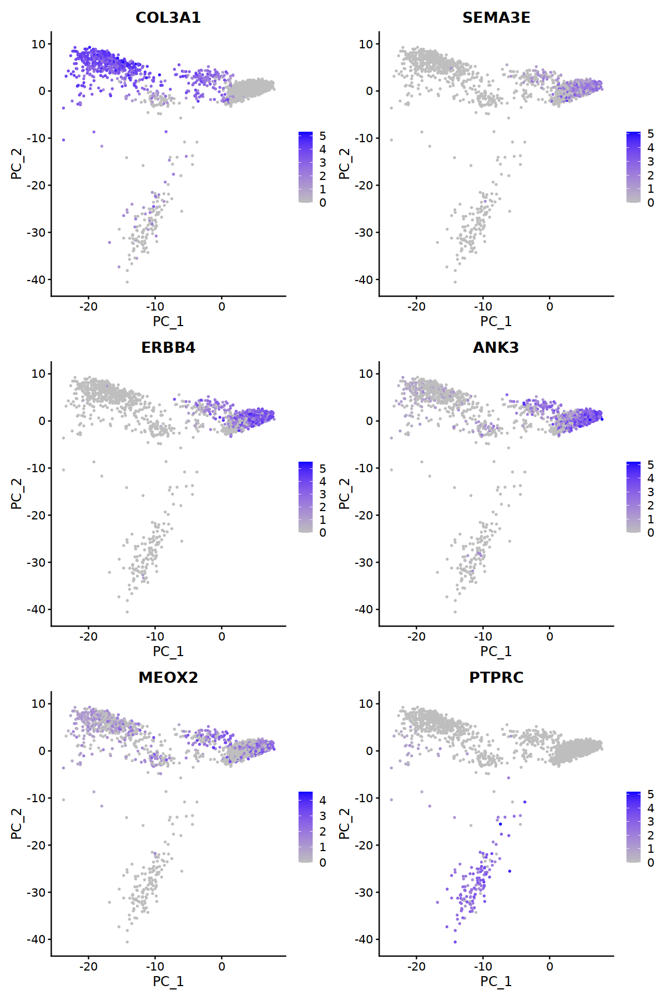

In [20]:
options(repr.plot.width = 10, repr.plot.height = 15)
FeaturePlot(seurat_obj, reduction = "pca", 
            feature=markers, ncol=2,
            cols = c("gray", "blue"),  min.cutoff = 0)

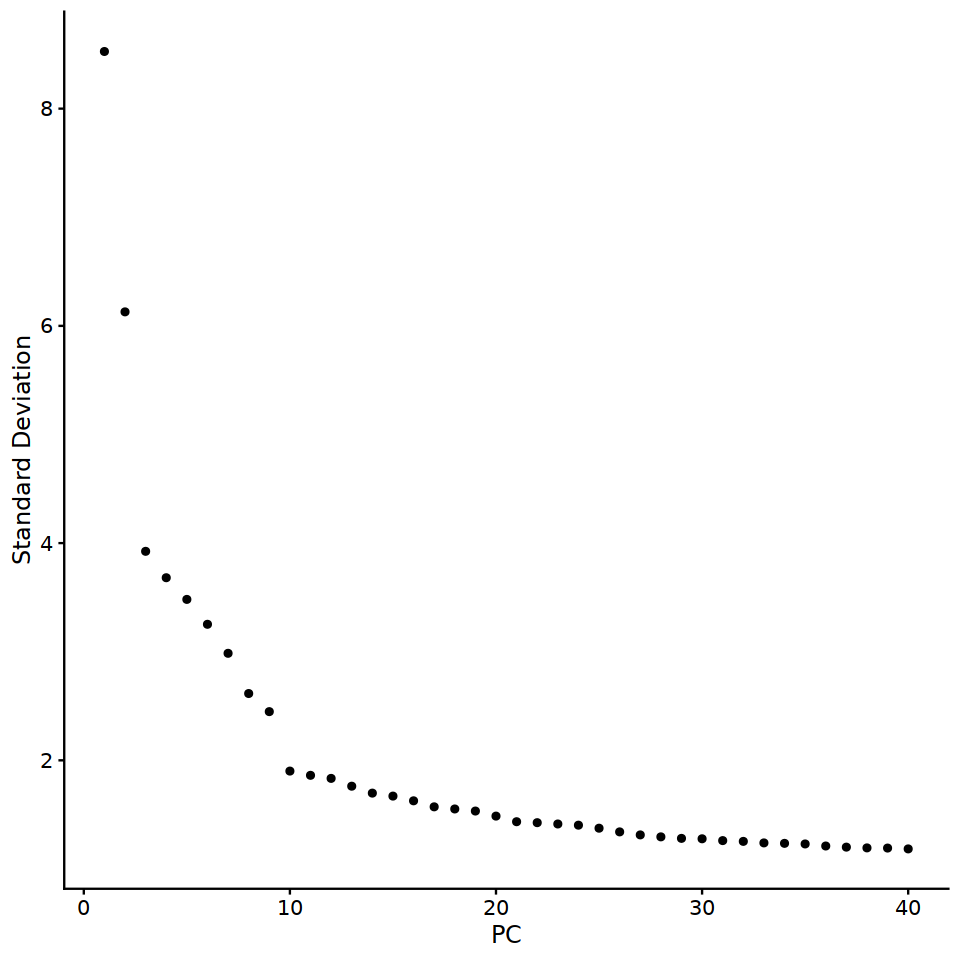

In [21]:
options(repr.plot.width = 8, repr.plot.height = 8)
ElbowPlot(seurat_obj, n=40)

In [22]:
seurat_obj <- RunUMAP(
  seurat_obj,
  dims = dcomp$rna,
  reduction = "pca",
  reduction.key = "rnaUMAP_",
   assay.use = assay_ch,
)

Suggested parameter: assay instead of assay.use


14:56:42 UMAP embedding parameters a = 0.9922 b = 1.112

14:56:42 Read 3446 rows and found 20 numeric columns

14:56:42 Using Annoy for neighbor search, n_neighbors = 30

14:56:42 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:56:43 Writing NN index file to temp file /scratch_tmp/49729482/RtmpsPK4Hr/file13d9939a3b264

14:56:43 Searching Annoy index using 1 thread, search_k = 3000

14:56:44 Annoy recall = 100%

14:56:44 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:56:46 Initializing from normalized Laplacian + noise (using irlba)

14:56:46 Commencing optimization for 500 epochs, with 133898 positive edges

14:56:56 Optimization finished



In [23]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [24]:
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_"
)

14:57:05 UMAP embedding parameters a = 0.9922 b = 1.112

14:57:06 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

14:57:07 Initializing from normalized Laplacian + noise (using irlba)

14:57:07 Commencing optimization for 500 epochs, with 97550 positive edges

14:57:18 Optimization finished



In [25]:
seurat_obj <- Seurat::FindClusters(seurat_obj, resolution = as.numeric(reso),
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 3446
Number of edges: 110540

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9665
Number of communities: 8
Elapsed time: 0 seconds


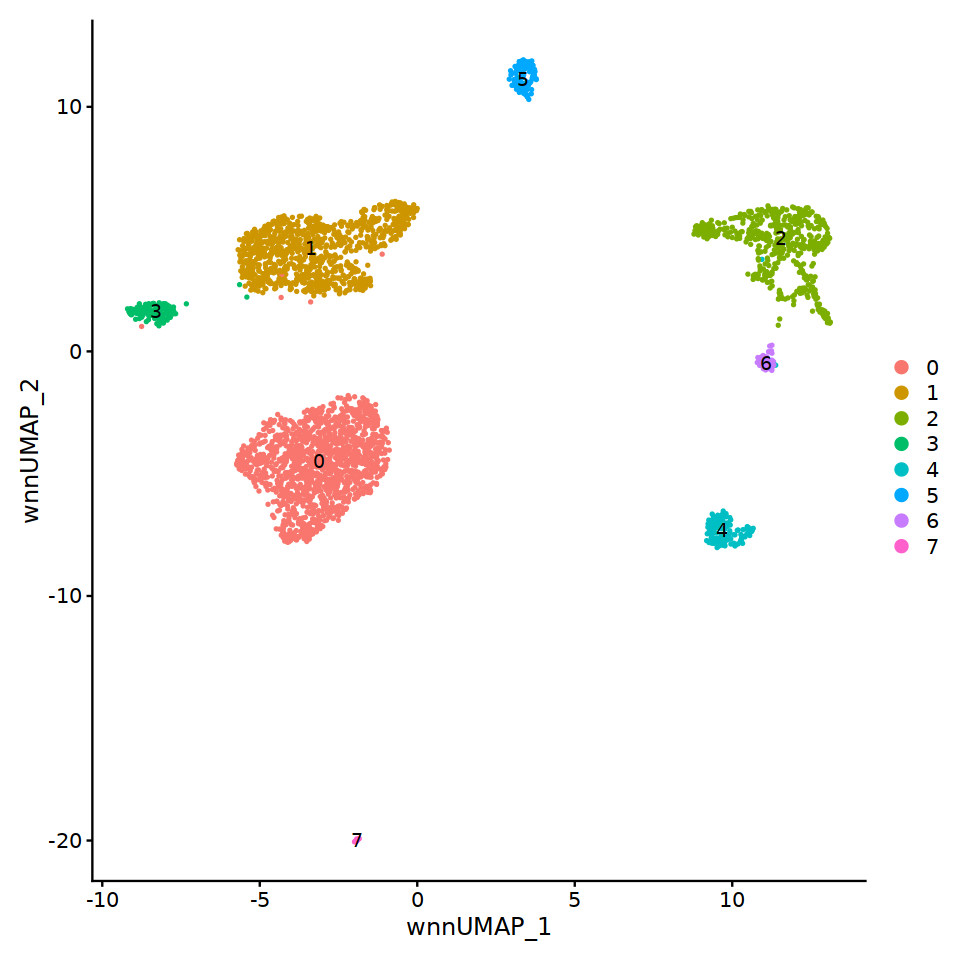

In [26]:
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

In [27]:
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7



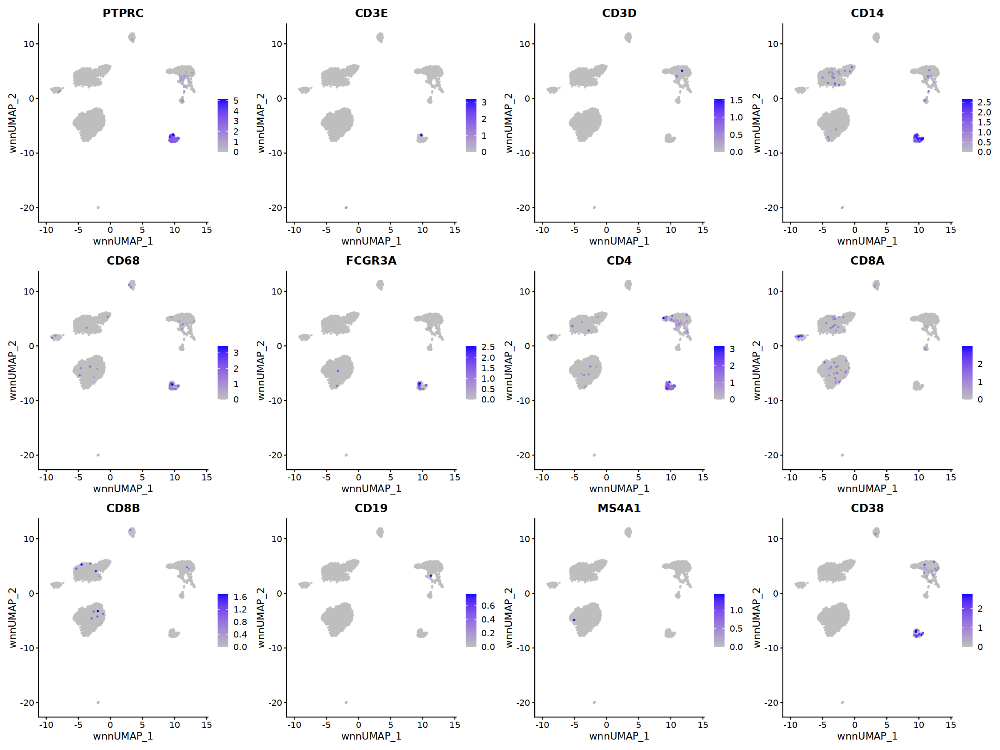

In [28]:
options(repr.plot.width = 20, repr.plot.height = 15)
immune <- c("PTPRC","CD3E", "CD3D", "CD14", "CD68", "FCGR3A", "CD4", "CD8A", "CD8B", "CD19", 
            "MS4A1", "CD38")

vars2plot <- exp_genes_plot(immune, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

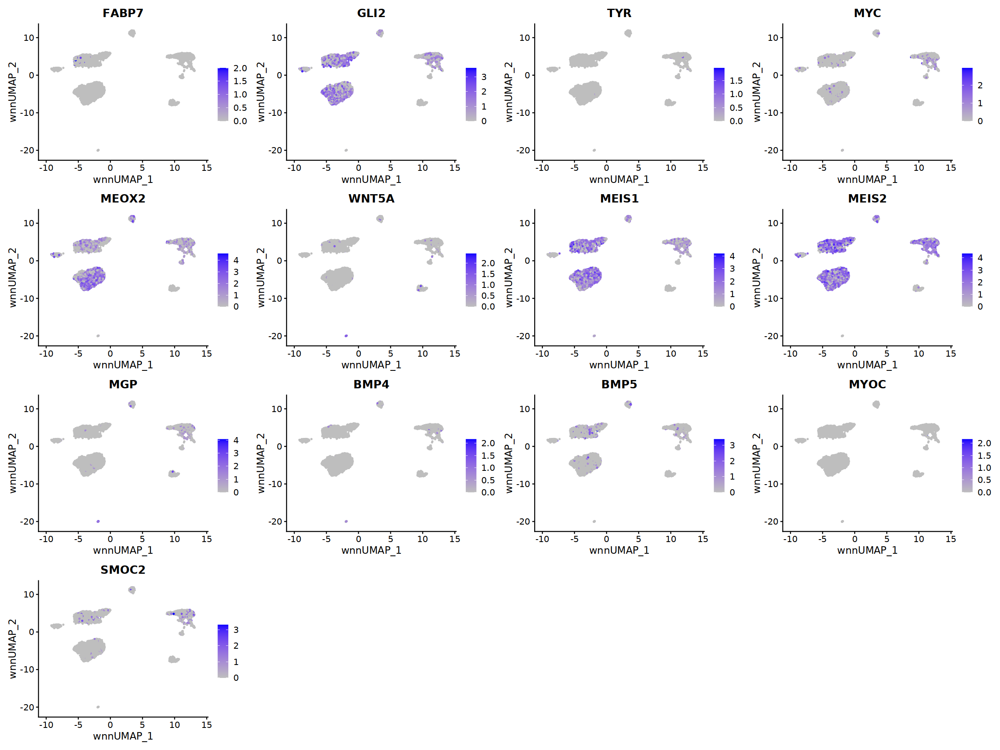

In [29]:
lite_tumor <- c("FABP7", "GLI2", "TYR", "MYC", "MEOX2", "WNT5A", "MEIS1", 
                "MEIS2", "MGP", "BMP4", "BMP5", "MYOC", "SMOC2")

vars2plot <- exp_genes_plot(lite_tumor, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"),  min.cutoff = 0)

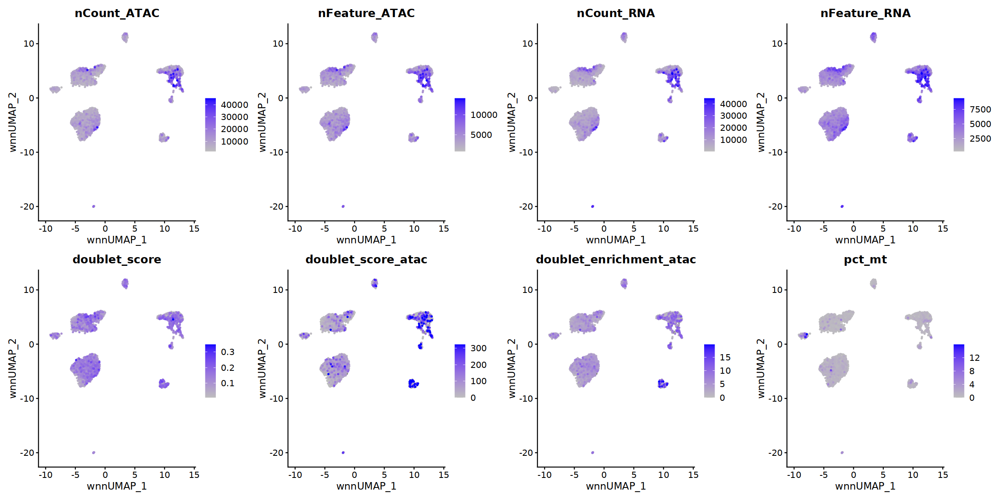

In [30]:
options(repr.plot.width = 20, repr.plot.height = 10)
qc_vars <- c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score","doublet_score_atac",
             "doublet_enrichment_atac", "pct_mt")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=qc_vars, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

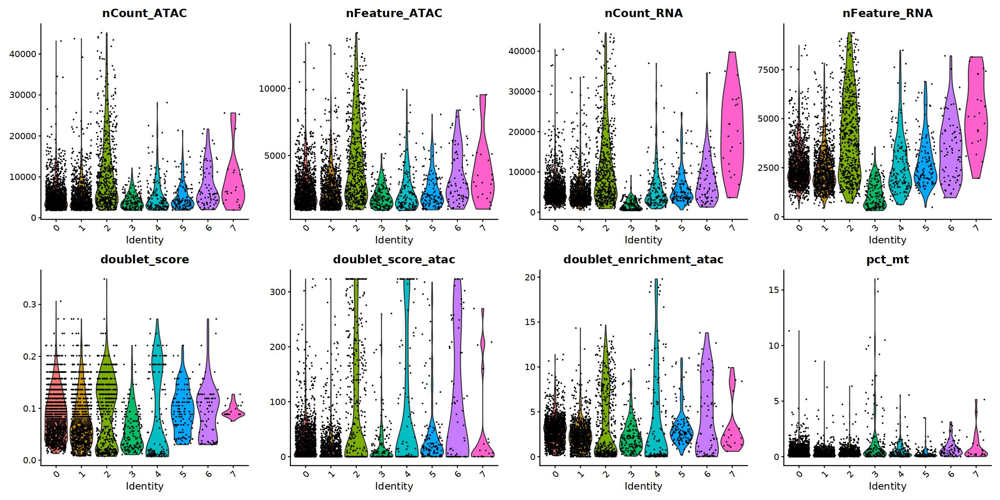

In [31]:
VlnPlot(seurat_obj,feature=qc_vars, ncol = 4)

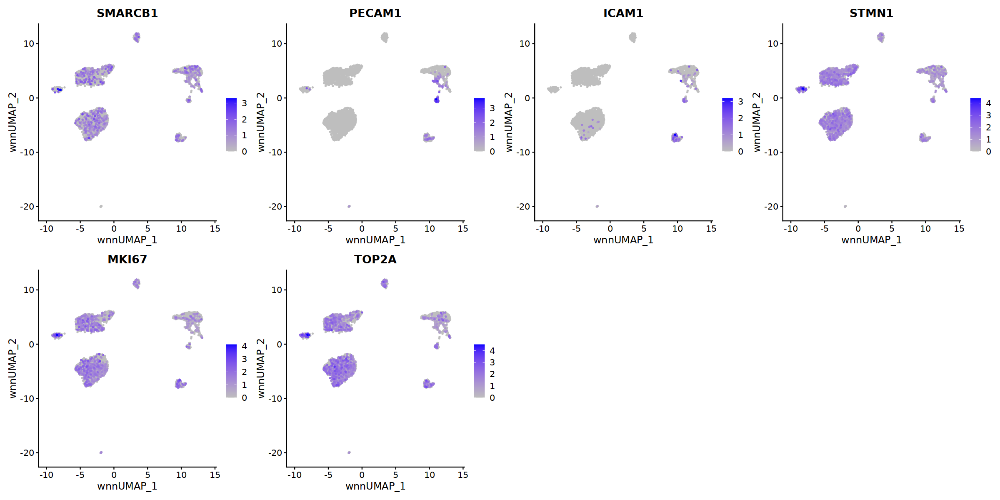

In [32]:
options(repr.plot.width = 20, repr.plot.height = 10)
other <- c("SMARCB1", "PECAM1","ICAM1","STMN1","MKI67","TOP2A")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=other, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

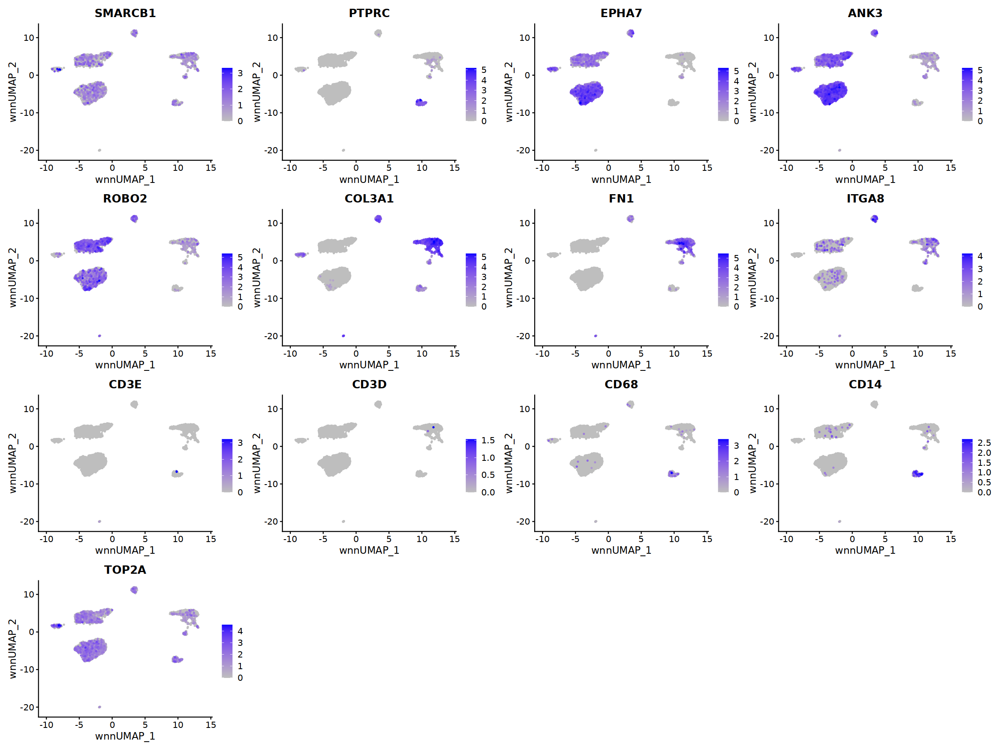

In [33]:
options(repr.plot.width = 20, repr.plot.height = 15)

vars2plot <- exp_genes_plot(c("SMARCB1","PTPRC", "EPHA7",
                              "ANK3","ROBO2", "COL3A1", "FN1",
                              "ITGA8", "CD3E", "CD3D","CD68","CD14",
                              "TOP2A"), seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

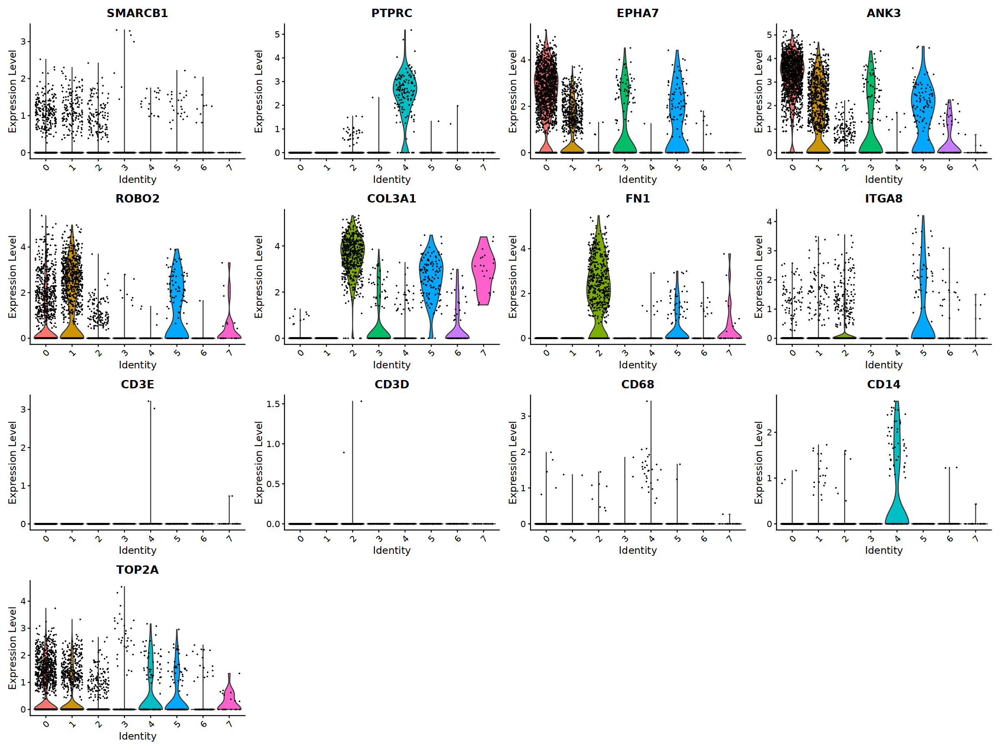

In [34]:
VlnPlot(seurat_obj,feature=vars2plot, ncol = 4)

Corresponding ST Visium image already shows adipocyte tissue adjacent to tumor

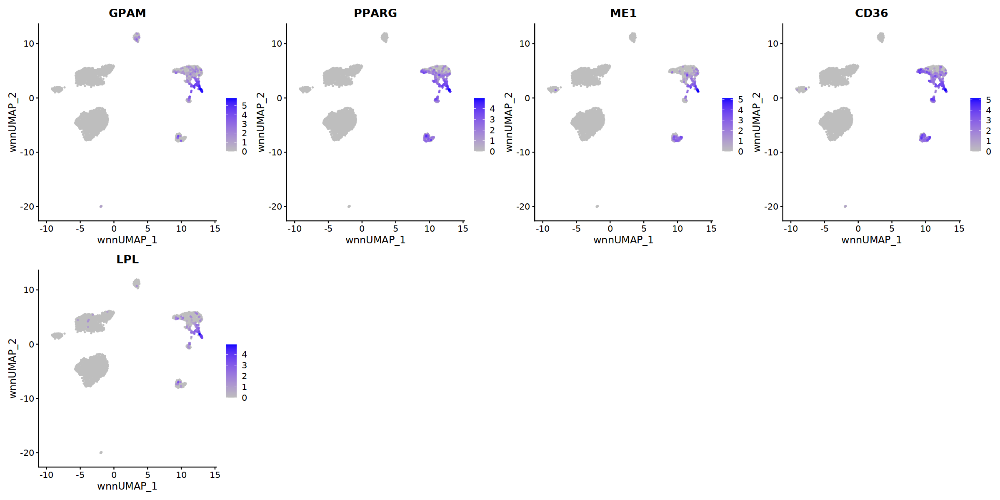

In [35]:
options(repr.plot.width = 20, repr.plot.height = 10)
adipo_markers <- c("GPAM", "PPARG", "ME1", "CD36", "LPL")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=adipo_markers, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

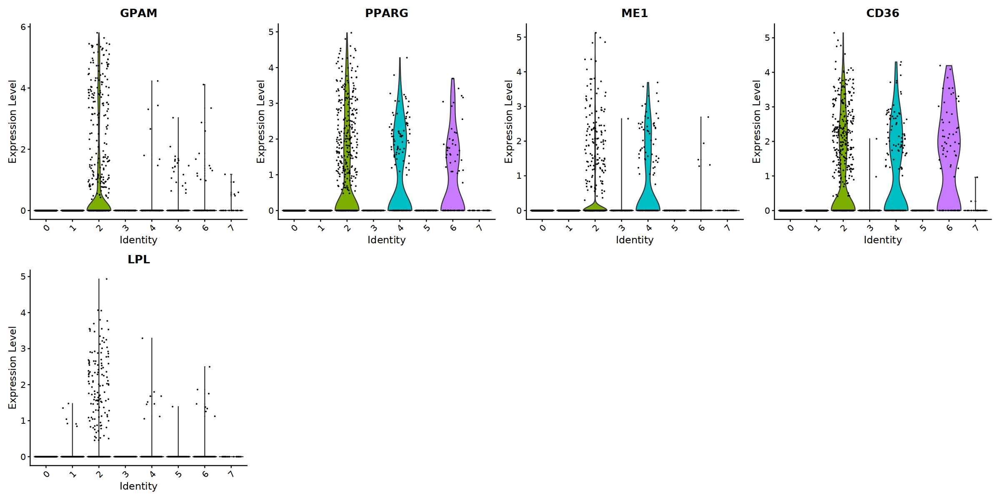

In [36]:
VlnPlot(seurat_obj, feature=adipo_markers, ncol = 4)

## Filter cells

Cluster 3 low quality cells 

In [37]:
rna.markers %>% 
  dplyr::filter(cluster == "3") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=30)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
RPL37A,3.820971e-13,2.0384805,0.641,0.661,1.169255e-08,3,RPL37A
RPL13A,1.337889e-18,2.0305361,0.765,0.778,4.094074e-14,3,RPL13A
RPS16,6.379618e-09,1.8787482,0.575,0.587,1.952227e-04,3,RPS16
RPS19,9.994758e-11,1.8037417,0.654,0.727,3.058496e-06,3,RPS19
EEF1A1,1.194149e-23,1.7020819,0.850,0.896,3.654214e-19,3,EEF1A1
RPL41,4.056423e-10,1.6614907,0.627,0.685,1.241306e-05,3,RPL41
VLDLR-AS12,8.748044e-07,0.6404039,0.118,0.333,2.676989e-02,3,VLDLR-AS1
SPIRE1,1.580716e-06,0.5884432,0.222,0.520,4.837149e-02,3,SPIRE1
REV3L1,1.116914e-13,0.5353216,0.392,0.846,3.417868e-09,3,REV3L


In [38]:
rna.markers %>% 
  dplyr::filter(cluster == "2") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=30)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
COL3A1,0.000000e+00,4.413073,0.987,0.083,0.000000e+00,2,COL3A1
CCDC102B,0.000000e+00,4.320280,0.837,0.044,0.000000e+00,2,CCDC102B
FN1,0.000000e+00,4.162535,0.806,0.023,0.000000e+00,2,FN1
COL1A1,0.000000e+00,4.127278,0.908,0.060,0.000000e+00,2,COL1A1
COL6A3,0.000000e+00,4.125130,0.934,0.041,0.000000e+00,2,COL6A3
COL4A2,0.000000e+00,4.062016,0.949,0.038,0.000000e+00,2,COL4A2
COL4A1,0.000000e+00,4.014945,0.932,0.027,0.000000e+00,2,COL4A1
GPAM,2.831457e-183,4.011091,0.358,0.016,8.664542e-179,2,GPAM
TNC,0.000000e+00,3.967797,0.475,0.000,0.000000e+00,2,TNC


Inspect cluster 2

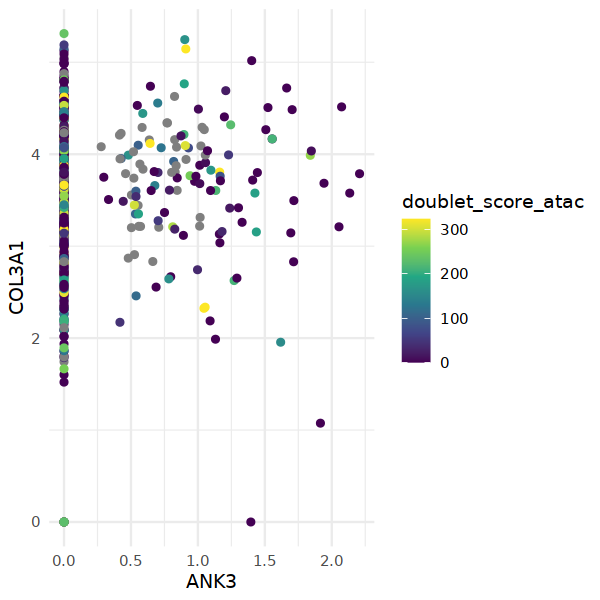

In [39]:
options(repr.plot.width = 5, repr.plot.height = 5)
data <- FetchData(seurat_obj, vars = c("seurat_clusters",
                                       "doublet_score_atac","nCount_RNA", 
                                       "COL3A1", "MEOX2", "MEIS2", 
                                       "PCDH9", "ERBB4", "ANK3", "PTPRC"))
data <- data[data$seurat_clusters == 2, ]
ggplot(data, aes(x = ANK3, y = COL3A1, color = doublet_score_atac)) + 
  geom_point() +
  theme_minimal() +
  scale_color_viridis_c()

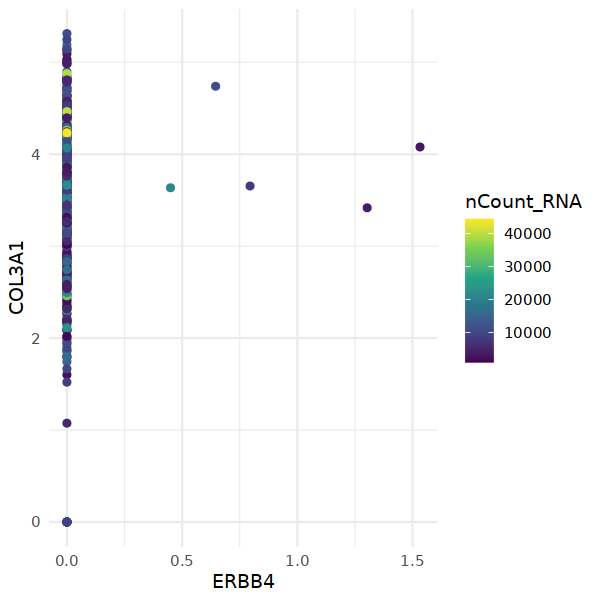

In [40]:
ggplot(data, aes(x = ERBB4, y = COL3A1, color = nCount_RNA)) + 
  geom_point() +
  theme_minimal() +
  scale_color_viridis_c()

Inspect cluster 4

In [41]:
data <- FetchData(seurat_obj, vars = c("seurat_clusters",
                                       "doublet_score_atac", 
                                       "COL3A1", "MEOX2", "MEIS2", "nCount_RNA", 
                                       "PCDH9", "ERBB4", "ANK3", "PTPRC"))
data <- data[data$seurat_clusters == 4, ]

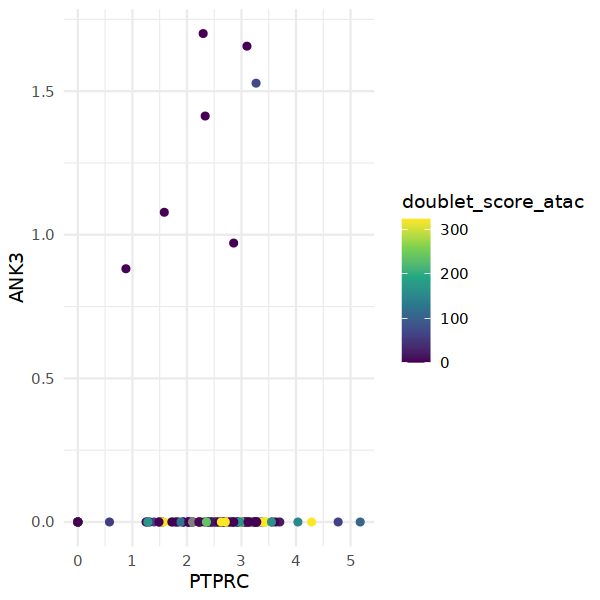

In [42]:
ggplot(data, aes(x = PTPRC, y = ANK3, color = doublet_score_atac)) + 
  geom_point() +
  theme_minimal() +
  scale_color_viridis_c()

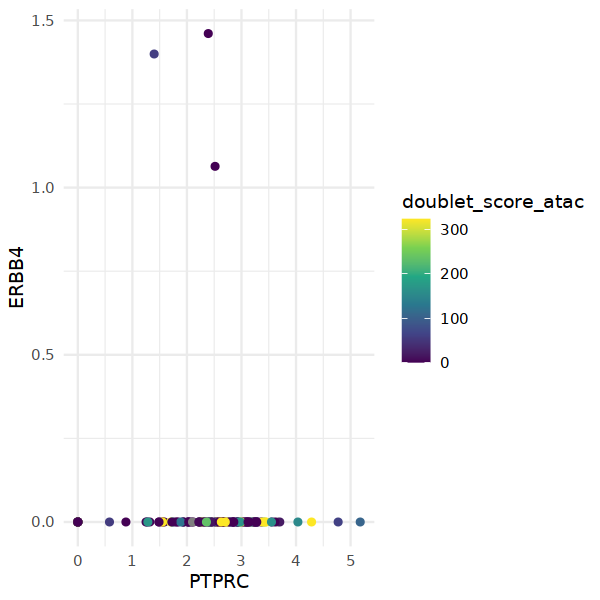

In [43]:
ggplot(data, aes(x = PTPRC, y = ERBB4, color = doublet_score_atac)) + 
  geom_point() +
  theme_minimal() +
  scale_color_viridis_c()

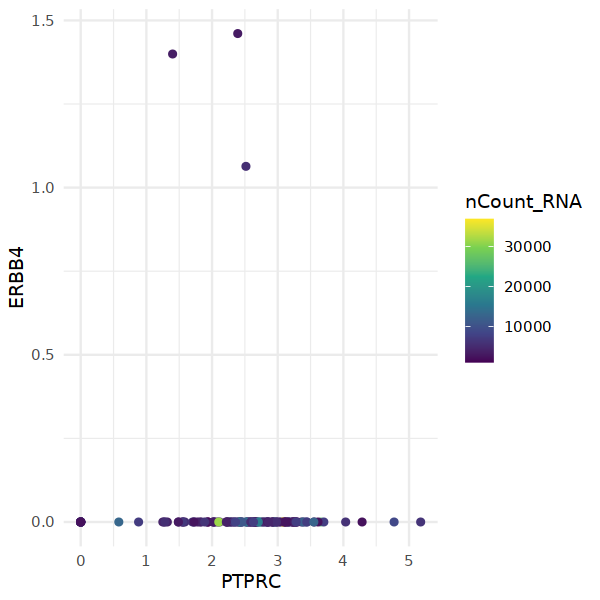

In [44]:
ggplot(data, aes(x = PTPRC, y = ERBB4, color = nCount_RNA)) + 
  geom_point() +
  theme_minimal() +
  scale_color_viridis_c()

Remove low quality cells and doublets from object

In [45]:
seurat_obj <- subset(seurat_obj, ident=3, invert=T)

## Re-process object after filtering

### RNA

In [46]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [47]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

In [48]:
sce

class: SingleCellExperiment 
dim: 30601 3293 
metadata(0):
assays(2): counts logcounts
rownames(30601): MIR1302-2HG AL627309.1 ... AC007325.4 AC007325.2
rowData names(0):
colnames(3293): AAACATGCAGGGAGCT-1 AAACCGAAGAGAAGGG-1 ...
  TTTGTTGGTGATTACG-1 TTTGTTGGTTTATCGC-1
colData names(38): orig.ident nCount_ATAC ... RNA_decontx.weight ident
reducedDimNames(3): PCA UMAP WNN.UMAP
mainExpName: RNA_decontx
altExpNames(2): RNA ATAC

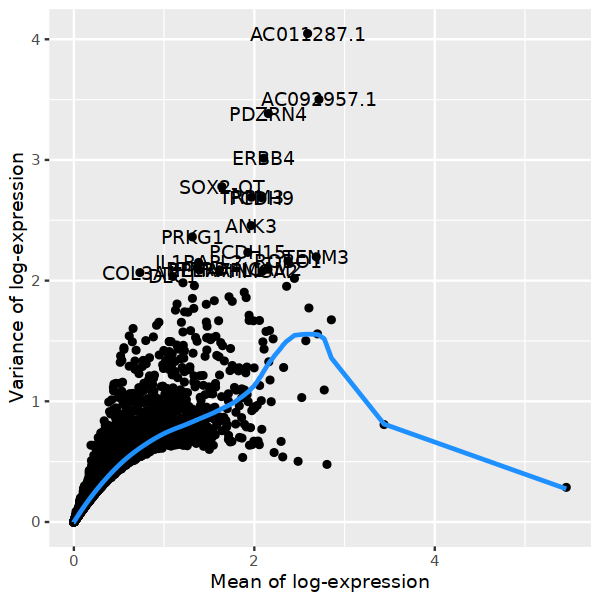

In [49]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [50]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  UBE2E2, COL4A2, COL3A1, COL4A1, RUNX1, COL6A3, IGFBP7, COL1A1, EBF1, ZEB2 
	   ATXN1, ITGA1, STARD13, ADAMTS12, COL12A1, CCDC102B, FN1, MIR4435-2HG, PDZRN3, DOCK10 
	   CYTOR, LAMB1, BICC1, MAN1A1, MYO1B, COL6A1, DCN, OSMR, GUCY1A2, SNTB1 
Negative:  AC092957.1, AC011287.1, PCDH15, HMGA2, TRPM3, PDZRN4, ERBB4, ANK3, GAS2, MAP2 
	   PCDH9, GRIP1, CUX2, EPHA7, IL1RAPL2, FGFR2, RMST, TOX, SOX2-OT, BRINP3 
	   SOX6, SEMA3E, SHROOM3, ADGRV1, SEMA3D, NXPH1, VWDE, FIGN, SCN3A, PRTG 
PC_ 2 
Positive:  DOCK2, PTPRC, SYK, FMN1, ATP8B4, DOCK8, TBXAS1, NPL, LYN, MSR1 
	   IKZF1, ADAP2, HCK, PIK3AP1, LCP2, PIK3R5, SPP1, CD163L1, MRC1, SLCO2B1 
	   CYBB, SRGN, VAV3, TFEC, ARHGAP15, ARHGAP25, CD163, LRMDA, MS4A7, KYNU 
Negative:  SLIT2, COL1A2, COL5A2, DLC1, PRKG1, CALD1, COL6A3, CCDC102B, LHFPL6, PDZRN3 
	   COL1A1, LAMA2, LAMA4, COL12A1, TENM4, ADAMTS12, PRICKLE1, BICC1, COL3A1, CDH11 
	   ITGA1, COL6A1, DCN, COL5A1, COL4A2, EDNRA, GUCY1A2, GUCY1

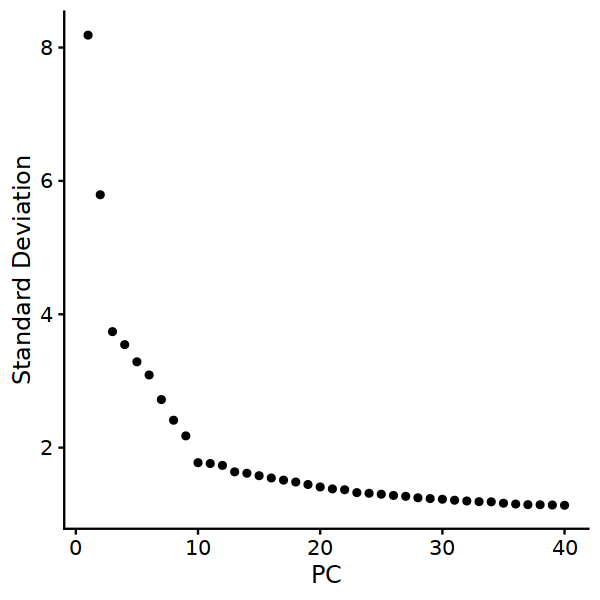

In [51]:
ElbowPlot(seurat_obj, n=40)

### ATAC

In [52]:
DefaultAssay(seurat_obj) <- "ATAC" # for individual analysis
seurat_obj <- RunTFIDF(seurat_obj)

Performing TF-IDF normalization



In [53]:
seurat_obj <- FindTopFeatures(seurat_obj, min.cutoff = "q75")
seurat_obj <- RunSVD(seurat_obj, reduction.name = "lsi.atac")

Running SVD

Scaling cell embeddings



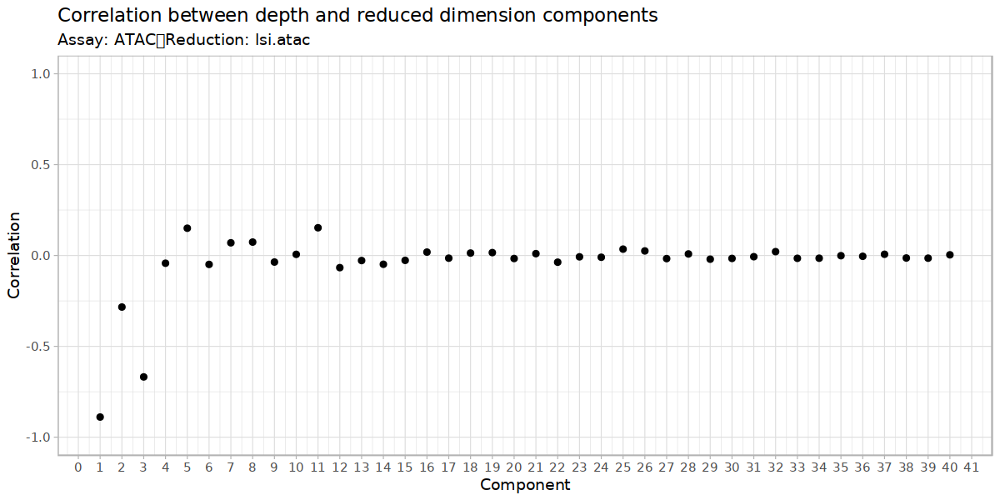

In [54]:
options(repr.plot.width = 10, repr.plot.height = 5)
DepthCor(seurat_obj, reduction = "lsi.atac", n=40)

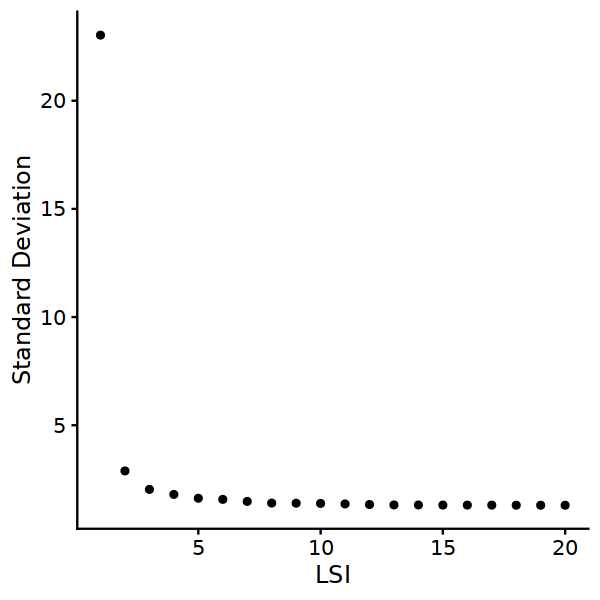

In [55]:
options(repr.plot.width = 5, repr.plot.height = 5)
ElbowPlot(seurat_obj, n=20, reduction="lsi.atac")

### Joint

In [56]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [57]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_",
   n.neighbors = 5, # avoid such compact groups of cells 
   min.dist = 1 # avoid such compact groups of cells 
)

15:00:27 UMAP embedding parameters a = 0.115 b = 1.929

15:00:27 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

15:00:29 Initializing from normalized Laplacian + noise (using irlba)

15:00:29 Commencing optimization for 500 epochs, with 92346 positive edges

15:00:39 Optimization finished



In [58]:
seurat_obj <- Seurat::FindClusters(seurat_obj, resolution = 0.1,
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 3293
Number of edges: 101996

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9725
Number of communities: 7
Elapsed time: 0 seconds


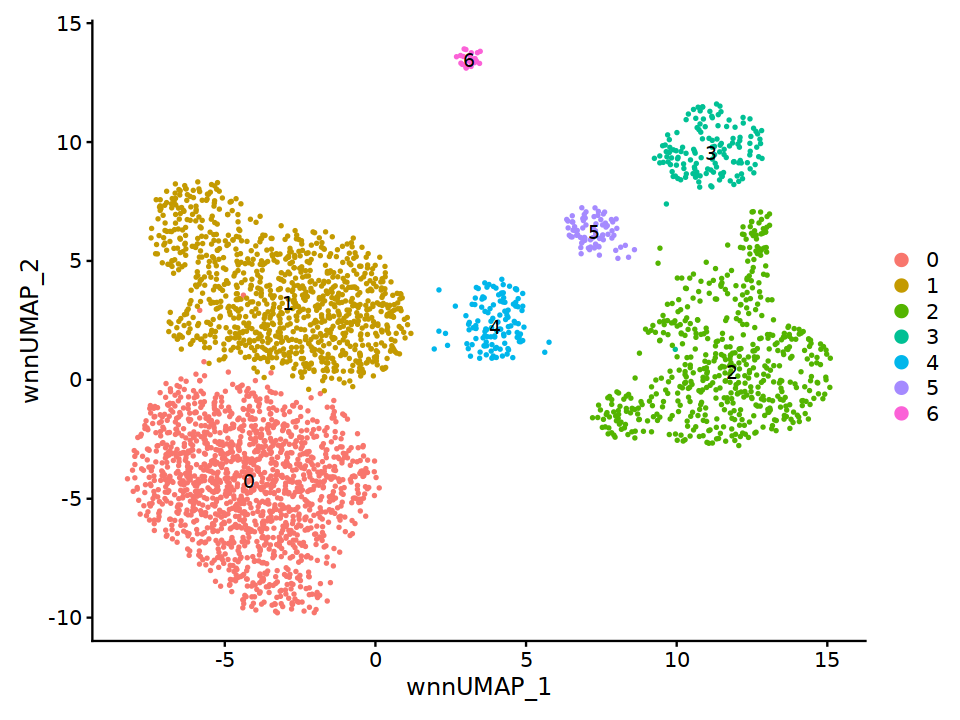

In [59]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

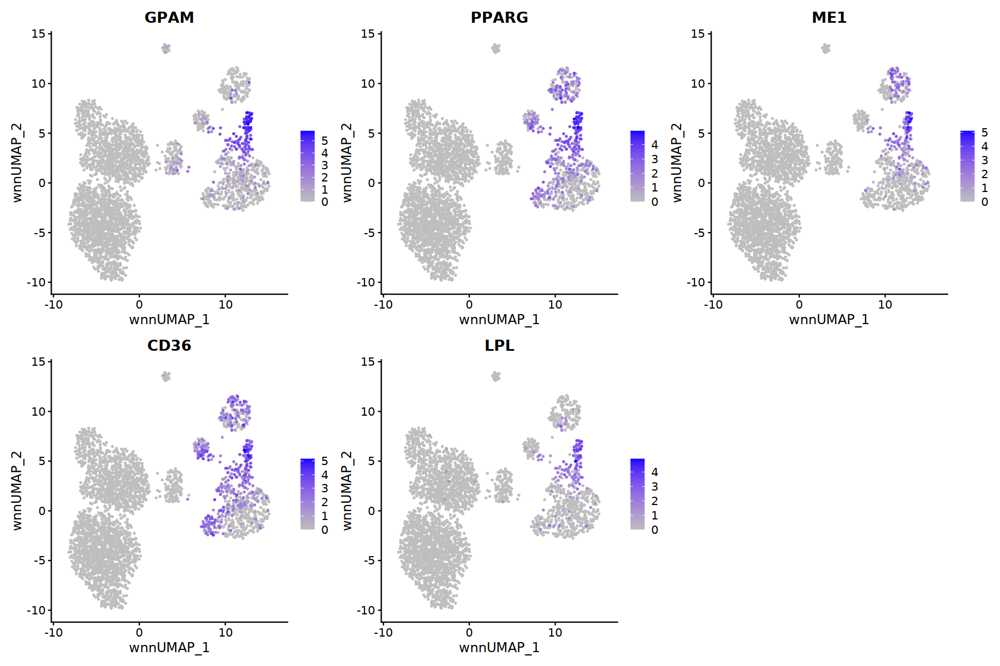

In [60]:
options(repr.plot.width = 15, repr.plot.height = 10)
FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=adipo_markers, ncol = 3, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

In [61]:
seurat_obj <- FindSubCluster(
  seurat_obj,
  cluster=2,
  graph.name = "wsnn",
  subcluster.name = "subclustering",
  resolution = 0.1,
  algorithm = 1
)

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 543
Number of edges: 18149

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9164
Number of communities: 2
Elapsed time: 0 seconds


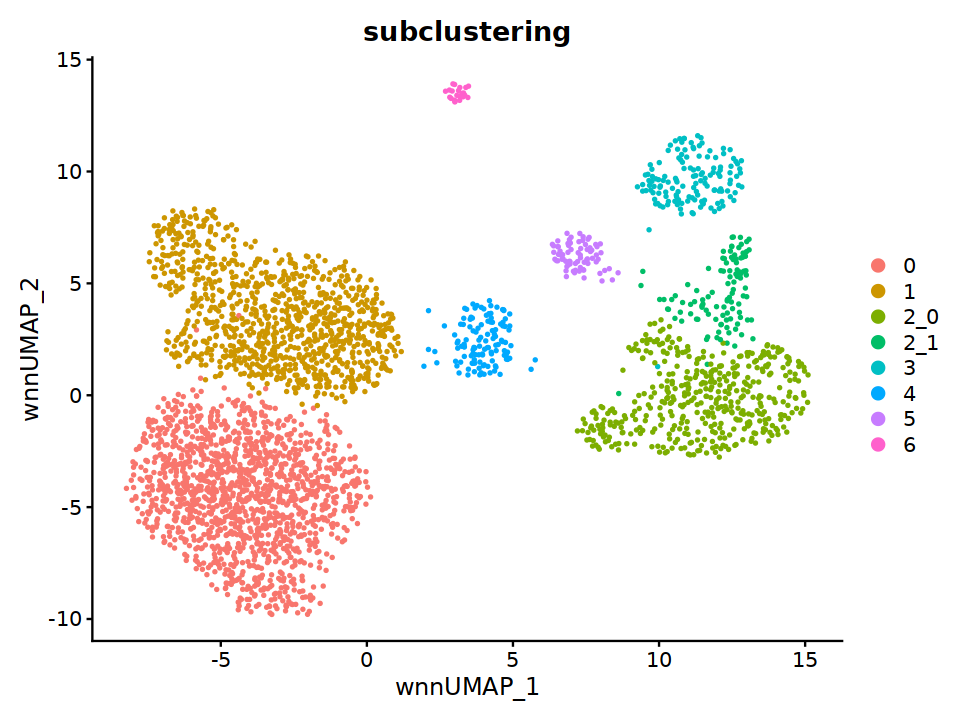

In [62]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap", group.by = "subclustering")

In [63]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$subclustering)

In [64]:
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, 
                              logfc.threshold = 0.2)

Calculating cluster 1

Calculating cluster 2_0

Calculating cluster 0

Calculating cluster 4

Calculating cluster 5

Calculating cluster 3

Calculating cluster 2_1

Calculating cluster 6



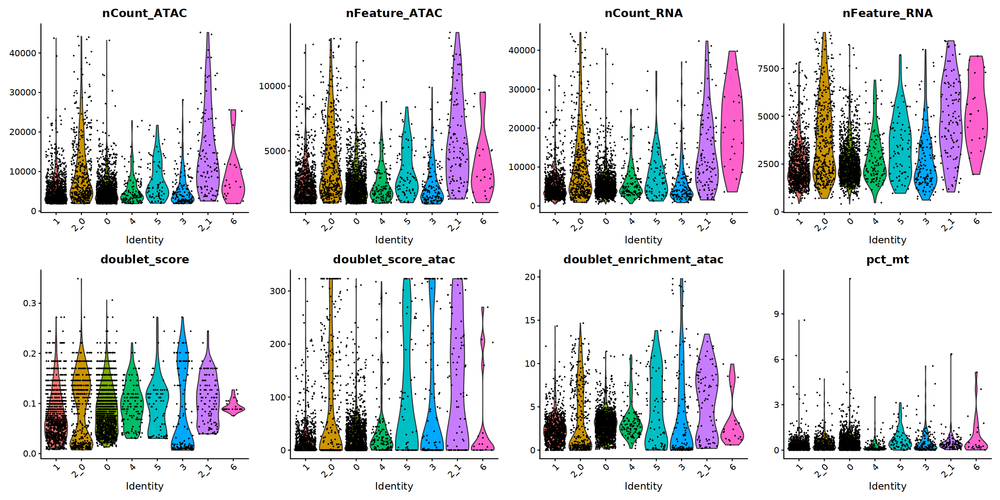

In [65]:
options(repr.plot.width = 20, repr.plot.height = 10)
VlnPlot(seurat_obj, feature=qc_vars, ncol = 4)

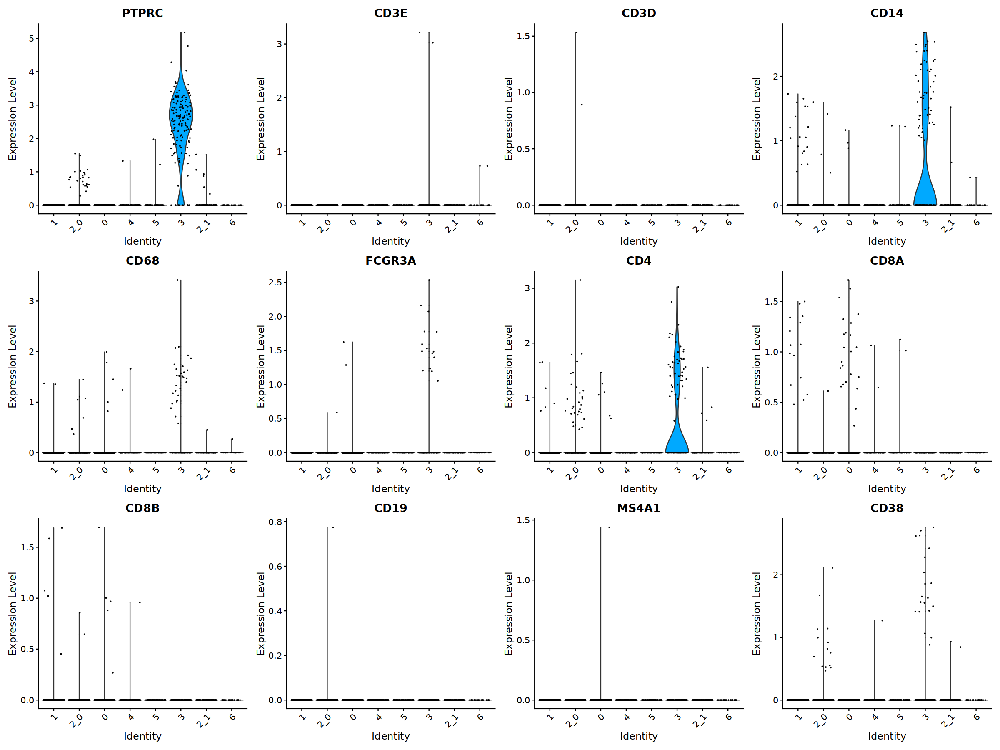

In [66]:
options(repr.plot.width = 20, repr.plot.height = 15)
immune <- c("PTPRC","CD3E", "CD3D", "CD14", "CD68", "FCGR3A", "CD4", "CD8A", "CD8B", "CD19", 
            "MS4A1", "CD38")

vars2plot <- exp_genes_plot(immune, seurat_obj)

VlnPlot(seurat_obj, feature=vars2plot, ncol = 4)

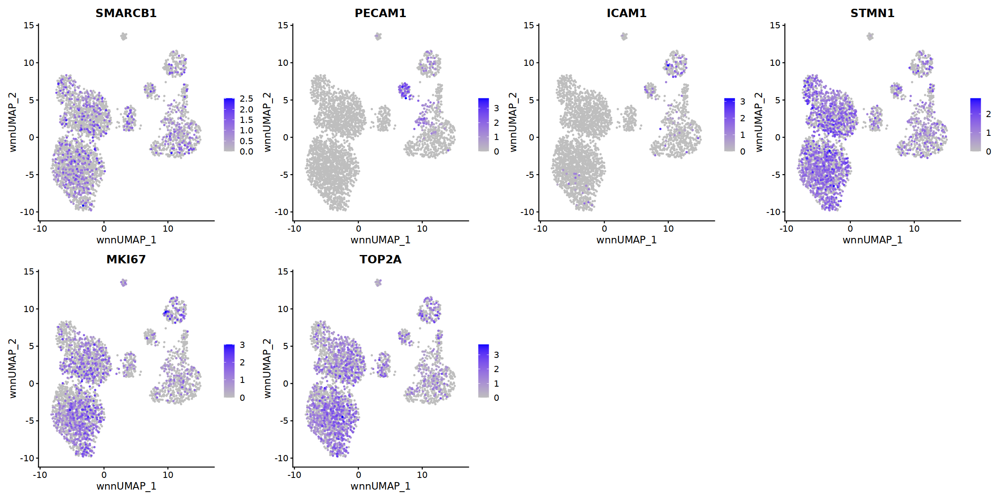

In [67]:
options(repr.plot.width = 20, repr.plot.height = 10)
other <- c("SMARCB1", "PECAM1","ICAM1","STMN1",
           "MKI67","TOP2A")

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=other, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

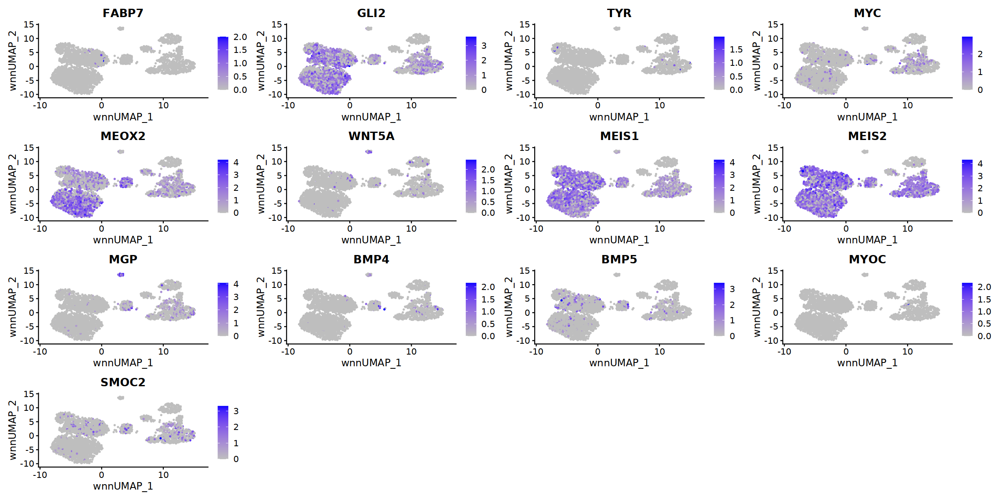

In [68]:
lite_tumor <- c("FABP7", "GLI2", "TYR", "MYC", "MEOX2", "WNT5A", "MEIS1", 
                "MEIS2", "MGP", "BMP4", "BMP5", "MYOC", "SMOC2")

vars2plot <- exp_genes_plot(lite_tumor, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"),  min.cutoff = 0)

In [69]:
rna.markers %>% 
  dplyr::filter(cluster == "2_1") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=50)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
GPAM,0.000000e+00,6.098433,0.972,0.042,0.000000e+00,2_1,GPAM
PPARG2,6.620016e-214,4.377306,0.982,0.084,2.025791e-209,2_1,PPARG
ACSL11,3.689725e-259,4.166123,0.991,0.064,1.129093e-254,2_1,ACSL1
SCD,8.577658e-130,3.936646,0.807,0.099,2.624849e-125,2_1,SCD
TSHR,0.000000e+00,3.930995,0.862,0.027,0.000000e+00,2_1,TSHR
ME11,4.956441e-283,3.912482,0.862,0.034,1.516720e-278,2_1,ME1
CD363,1.993491e-192,3.723079,0.991,0.092,6.100280e-188,2_1,CD36
ACACB,1.990872e-115,3.681124,0.972,0.206,6.092266e-111,2_1,ACACB
LPL,0.000000e+00,3.661693,0.862,0.019,0.000000e+00,2_1,LPL


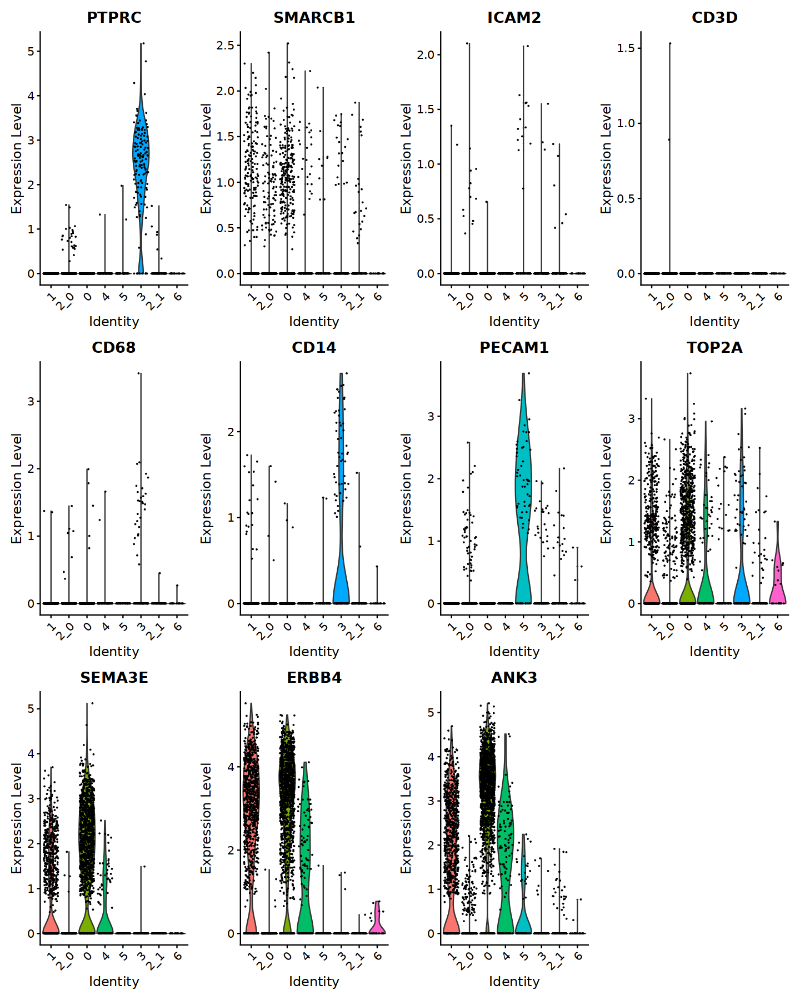

In [70]:
options(repr.plot.width = 12, repr.plot.height = 15)
VlnPlot(seurat_obj, feature=c("PTPRC", "SMARCB1", "ICAM2", "CD3D",
                              "CD68", "CD14", "PECAM1", "TOP2A",
                              "SEMA3E","ERBB4", "ANK3"), 
        ncol = 4, pt.size=0.01)

### Rename

In [71]:
rename_clusters <- c("0"="Tumor EPHA7", "1"="Tumor GRIN2A",
                     "2_0"="Fibroblast 1", "2_1"="Adipocytes",
                     "3"="Monocytes-Macrophages", 
                     "4"="Tumor CDH11", "5"="Endothelial cells",
                     "6"="Fibroblast 2")

seurat_obj <- RenameIdents(object = seurat_obj, rename_clusters)
seurat_obj$clusters <- Idents(seurat_obj)

In [72]:
cols_keep <- c('nCount_ATAC', 'nFeature_ATAC', 'nCount_RNA', 'nFeature_RNA', 
               'is_cell', 'atac_fragments', 'atac_peak_region_fragments', 
               'fragments', 'mononucleosomal', 'nucleosome_free', 'reads_count', 
               'FRiP', 'caller', 'nucleosome_signal', 'nucleosome_percentile', 
               'TSS.enrichment', 'TSS.percentile', 'high.tss', 'pct_mt', 
               'pct_ribosomal', 'doublet_score', 'doublet_pred', 'doublet_score_atac',
               'doublet_enrichment_atac', 'S.Score', 'G2M.Score', 'Phase',
               'RNA.weight', 'ATAC.weight', 'nCount_RNA_decontx','nFeature_RNA_decontx', 
               'RNA_decontx.weight','seurat_clusters','clusters')

seurat_obj@meta.data <- seurat_obj@meta.data[,cols_keep] 

In [73]:
rna.markers <- rna.markers %>% 
      mutate(cluster = as.character(cluster)) %>% 
      mutate(annotation = rename_clusters[cluster])

In [74]:
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.csv")))

In [75]:
df_meta <- seurat_obj@meta.data

df_meta <- df_meta %>% 
      mutate(cell_groups = case_when(
      str_detect(clusters, "Tumor") ~ "Tumor",
      clusters == "Immune Cells" | clusters == "T-cells" | clusters == 'Plasma B-cell' ~ "Immune",
      str_detect(clusters, "Macrophage") ~ "Immune",
      TRUE ~ "Other stromal"))

seurat_obj@meta.data$cell_groups <- df_meta$cell_groups

In [76]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$cell_groups)
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l1_anno_{patient}.csv")))

Calculating cluster Tumor

Calculating cluster Other stromal

Calculating cluster Immune



In [77]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

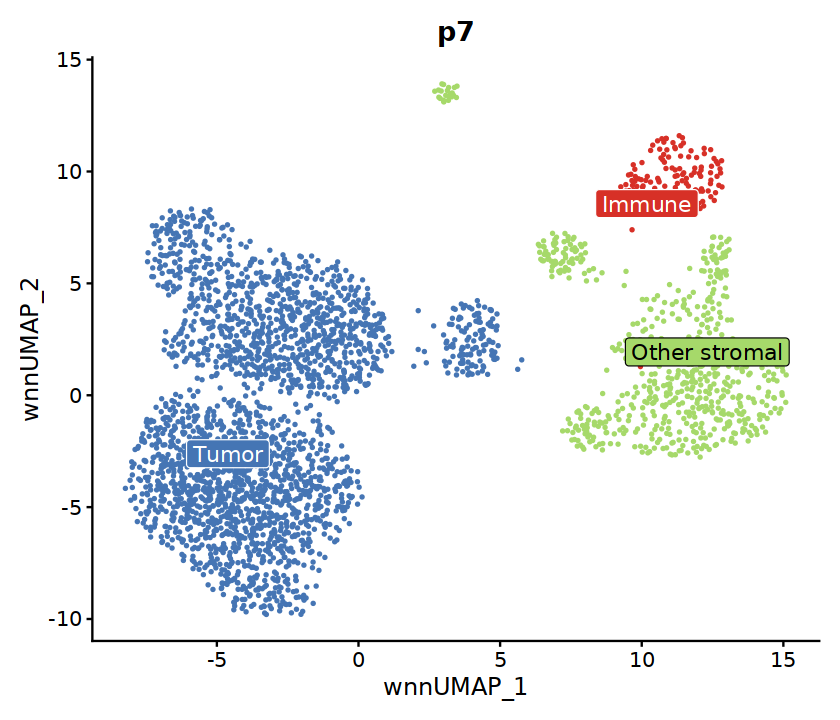

In [78]:
options(repr.plot.width = 7, repr.plot.height = 6)
l1 <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        repel = TRUE,
        label.color = as.list(color_labels),
        cols = c("Immune"="#d73027", "Other stromal"="#a6d96a","Tumor"="#4575b4")) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
l1

In [79]:
ggsave(plot = l1, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l1.svg")))

In [80]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$clusters)

In [81]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

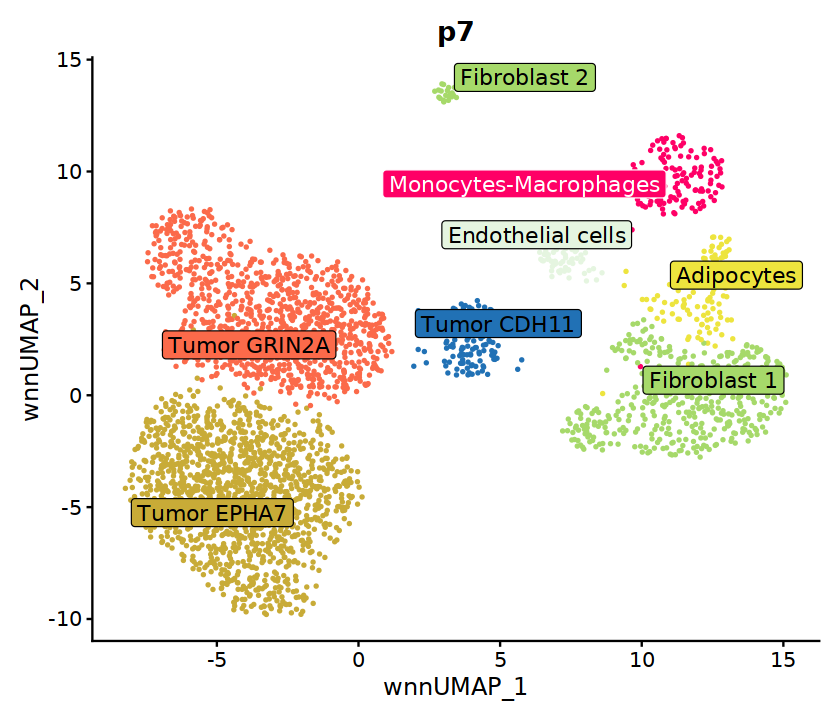

In [82]:
options(repr.plot.width = 7, repr.plot.height = 6)
p_clust <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))

p_clust

In [83]:
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP.svg")))
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l2.png")))

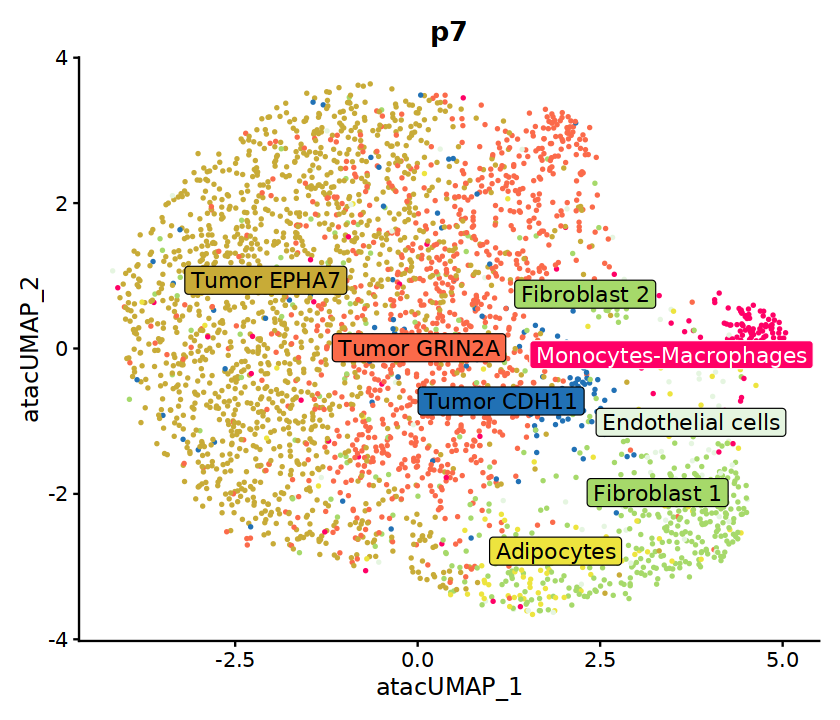

In [84]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(seurat_obj, 
        reduction = "umap.atac", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))


In [85]:
# Calculate the variance explained 
stdev <- Stdev(seurat_obj, reduction = "pca")

var_explained <- (stdev^2) / sum(stdev^2) * 100

pc1_label <- paste0("PC1: ", round(var_explained[1], 2), "% var.")
pc2_label <- paste0("PC2: ", round(var_explained[2], 2), "% var.")

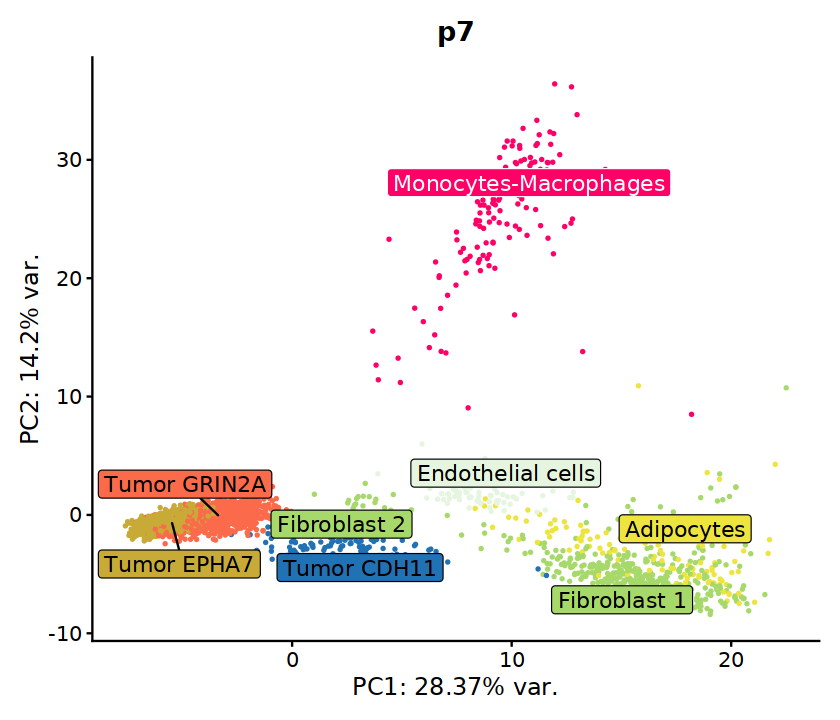

In [86]:
p_pca <- DimPlot(seurat_obj, 
        reduction = "pca", 
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    xlab(pc1_label) +
    ylab(pc2_label) +
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_pca 

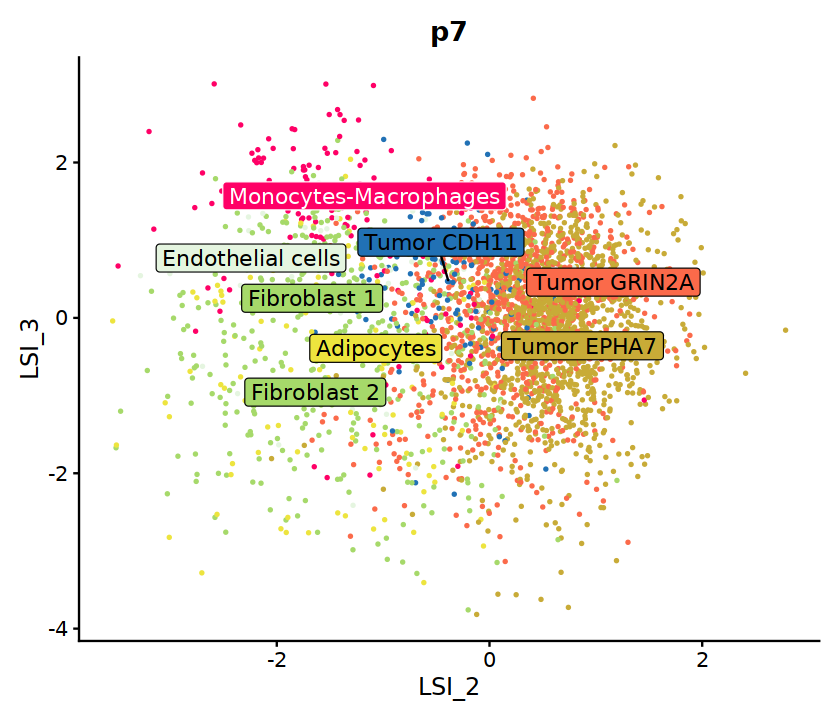

In [87]:
p_lsi <- DimPlot(seurat_obj, 
        reduction = "lsi.atac", 
        dims = c(2, 3),
        label = T,
        label.box = TRUE,
        label.size = 4.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_lsi

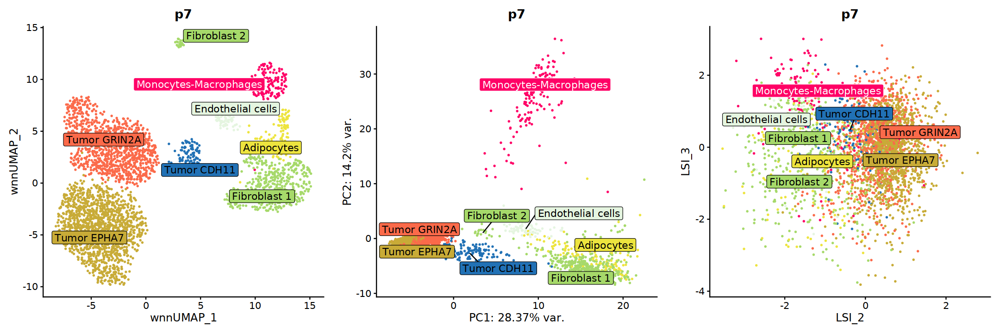

In [88]:
options(repr.plot.width = 18, repr.plot.height = 6)
cp <- cowplot::plot_grid(p_clust, p_pca, p_lsi,
                   align = "hv",
                   axis = "trbl",
                   ncol = 3,
                   nrow = 1)
cp

In [89]:
ggsave(plot = cp, width = 18, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_reductions.png")))

Pseudo-bulk per cluster

In [90]:
var_name <- paste0("markers_", patient)
markers_clust <- get(var_name)

markers <- unlist(markers_clust, use.names = F)
markers <- c(c("MEOX2", "MEIS2"), markers) ## common markers to all clusters

In [91]:
Idents(seurat_obj) <- factor(Idents(seurat_obj), levels = names(markers_clust))

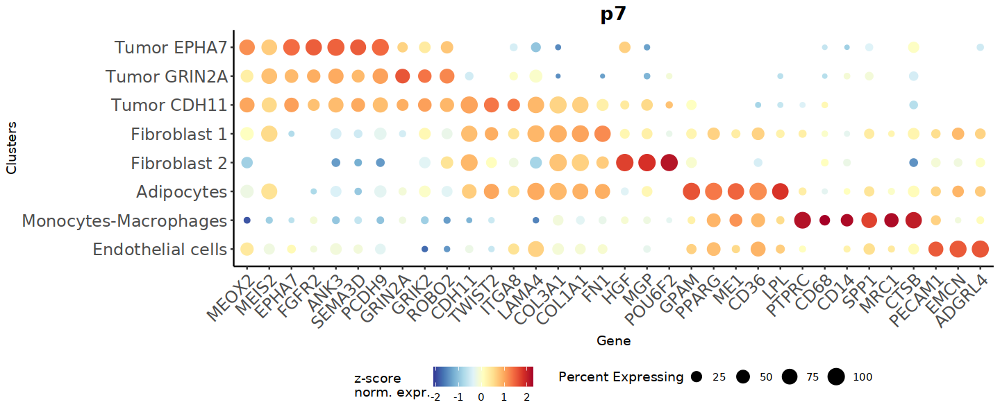

In [92]:
options(repr.plot.width = 12, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp1 <- custom_dp(seurat_obj, markers, TRUE,patient)
dp1

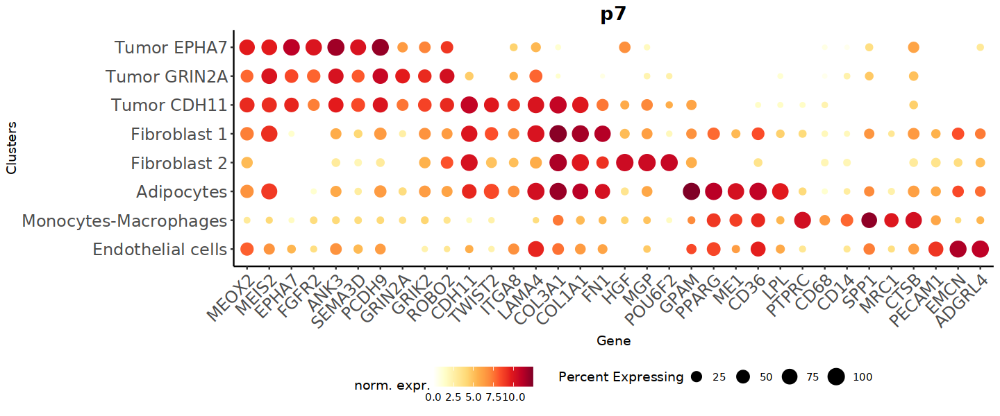

In [93]:
options(repr.plot.width = 12, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp2 <- custom_dp(seurat_obj, markers, FALSE,patient)
dp2

In [94]:
ggsave(plot = dp1, width = 12, height = 5, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_dotplot.svg")))

## Save

In [95]:
# keep original metrics
seurat_obj$ncount_rna <- seurat_obj$nCount_RNA
seurat_obj$nfeature_rna <- seurat_obj$nFeature_RNA

In [96]:
seurat_obj$RNA <- NULL
seurat_obj[['RNA']] = seurat_obj[[assay_ch]]
DefaultAssay(seurat_obj) <- "RNA"
seurat_obj$RNA_decontx <- NULL

In [97]:
saveRDS(seurat_obj, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.rds")))

## Session

In [98]:
sessionInfo()

R version 4.1.1 (2021-08-10)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: CentOS Linux 7 (Core)

Matrix products: default
BLAS/LAPACK: /home/groups/singlecell/isentis/conda_envs/ines_r4.1.1c/lib/libopenblasp-r0.3.24.so

locale:
 [1] LC_CTYPE=es_ES.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=es_ES.UTF-8        LC_COLLATE=es_ES.UTF-8    
 [5] LC_MONETARY=es_ES.UTF-8    LC_MESSAGES=es_ES.UTF-8   
 [7] LC_PAPER=es_ES.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=es_ES.UTF-8 LC_IDENTIFICATION=C       

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] scater_1.22.0               scran_1.22.1               
 [3] scuttle_1.4.0               SingleCellExperiment_1.16.0
 [5] SummarizedExperiment_1.24.0 Biobase_2.54.0             
 [7] GenomicRanges_1.46.1        GenomeInfoDb_1.30.1        
 [9] IRanges_2.28.0    